# 06 · Inferencia estadística — PowerShift AI (Probabilidad y Estadística II)
Tres pruebas de hipótesis con las funciones del **Formulario Oficial** del curso: PDF escritas a mano (`normal`, `gauss`, `tdist`, `chi2`, `Fdist`), probabilidades con `scipy.integrate.quad` y valores críticos por barrido con `np.linspace`. **No se usa `scipy.stats`.**

**Entradas:** `datos_horarios.csv` (notebook 00) y `costos_diarios.csv` (notebook 04).

| # | Prueba | Variable | H0 (en palabras) |
|---|---|---|---|
| 1 | t pareada | costo diario de las cargas controlables, sin vs. con orquestador (n = 30 días con carga de EV) | El costo medio diario sin el orquestador es igual al costo medio con él. |
| 2 | ANOVA 1 factor | potencia de la bomba de calor por franja horaria (invierno) | El consumo medio de la bomba de calor es el mismo en las tres franjas. |
| 3 | χ² bondad de ajuste | potencia que la vivienda toma de la red entre 01:00 y 05:00 h | El consumo nocturno de la vivienda sigue una distribución Normal. |

Nivel de significancia: α = 0.05. Las muestras se eligen al azar con semilla fija (se fijó antes de ver resultados; no se ajustó).

In [1]:
import json, warnings
import numpy as np
import pandas as pd
import scipy.integrate as integrate
from scipy.special import gamma
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=integrate.IntegrationWarning)
ALFA = 0.05
SEMILLA = 42
resultados = {}

## Funciones del formulario (PDF a mano)

In [2]:
def normal(z):
    return (1.0 / np.sqrt(2.0 * np.pi)) * np.exp(-0.5 * z**2)

def gauss(x, mu, sigma):
    return (1.0 / (np.sqrt(2.0 * np.pi) * sigma)) * np.exp(-((x - mu)**2) / (2.0 * sigma**2))

def tdist(t, nu):
    coef = gamma((nu + 1.0) * 0.5) / (np.sqrt(np.pi * nu) * gamma(nu * 0.5))
    return coef * (1.0 + (t**2) / nu)**(-(nu + 1.0) * 0.5)

def chi2(x, nu):
    if x <= 0: return 0.0
    coef = 1.0 / ((2.0**(nu * 0.5)) * gamma(nu * 0.5))
    return coef * (x**(nu * 0.5 - 1.0)) * np.exp(-x * 0.5)

def Fdist(f, nu1, nu2):
    if f <= 0: return 0.0
    num = gamma((nu1 + nu2) * 0.5) * ((nu1 / nu2)**(nu1 * 0.5)) * (f**(nu1 * 0.5 - 1.0))
    den = gamma(nu1 * 0.5) * gamma(nu2 * 0.5) * ((1.0 + (nu1 / nu2) * f)**((nu1 + nu2) * 0.5))
    return num / den

## Funciones auxiliares (integración y barrido)
- `cola_derecha`: P(X ≥ x0) integrando la PDF de x0 a ∞ (valor p de cola derecha).
- `critico`: valor v tal que P(X ≤ v) alcanza una probabilidad dada, barriendo una malla `np.linspace` (patrón visto en clase).
- `chi2_normalidad`: prueba de bondad de ajuste χ² de normalidad con k clases equiprobables bajo la Normal ajustada (ν = k − 1 − 2).

In [3]:
def cola_derecha(pdf, x0, *args):
    p, _ = integrate.quad(pdf, x0, np.inf, args=args)
    return p

def critico(pdf, args, prob, lim_inf, a, b, n=20000):
    for v in np.linspace(a, b, n):
        p, _ = integrate.quad(pdf, lim_inf, v, args=args)
        if p >= prob:
            return float(v)
    return float("nan")

_zcache = {}
def z_cuantil(q):
    if q not in _zcache:
        _zcache[q] = critico(normal, (), q, -np.inf, -6, 6)
    return _zcache[q]

def chi2_normalidad(x, k=4):
    x = np.asarray(x, dtype=float); n = len(x)
    mu, sigma = x.mean(), x.std(ddof=1)
    bordes = [-np.inf] + [mu + sigma * z_cuantil(i / k) for i in range(1, k)] + [np.inf]
    O = np.array([np.sum((x > bordes[i]) & (x <= bordes[i + 1])) for i in range(k)])
    E = np.full(k, n / k)
    chi0 = float(np.sum((O - E)**2 / E))
    nu = k - 1 - 2
    return {"n": n, "mu": mu, "sigma": sigma, "k": k, "nu": nu, "O": O.tolist(),
            "E": E.tolist(), "chi2_0": chi0, "p": cola_derecha(chi2, chi0, nu)}

In [5]:
costos = pd.read_csv("costos_diarios.csv")
horario = pd.read_csv("datos_horarios.csv", index_col=0, parse_dates=True)
print("Días con carga de EV (población de la prueba 1):", len(costos))
print("Días completos en total:", horario['fecha'].nunique())

Días con carga de EV (población de la prueba 1): 268
Días completos en total: 506


## Prueba 1 · t de Student pareada (costo diario)
**H0:** el costo medio diario de las cargas controlables (EV + bomba de calor) sin el orquestador es igual al costo medio con PowerShift AI (no hay ahorro).
**H1:** el costo medio sin el orquestador es mayor que con él (hay ahorro). Cola derecha.

$D_i = X_{1i} - X_{2i}$, $t_0 = \bar D / (S_D/\sqrt n)$, $\nu = n-1$. El escenario "con orquestador" es **simulado** (notebook 04).

In [6]:
rng1 = np.random.default_rng(SEMILLA)
idx = np.sort(rng1.choice(len(costos), size=30, replace=False))
muestra = costos.iloc[idx]
X1 = muestra["costo_sin"].to_numpy(); X2 = muestra["costo_con_noche"].to_numpy()
D = X1 - X2
n = len(D); Dbar = D.mean(); SD = D.std(ddof=1); se = SD / np.sqrt(n); t0 = Dbar / se; nu = n - 1

p1 = cola_derecha(tdist, t0, nu)
t_crit = critico(tdist, (nu,), 1 - ALFA, -np.inf, -10, 10)
t_025 = critico(tdist, (nu,), 0.975, -np.inf, -10, 10)
IC = (Dbar - t_025 * se, Dbar + t_025 * se)

print(f"X1 media = {X1.mean():.3f}  X2 media = {X2.mean():.3f}  D media = {Dbar:.3f}  SD = {SD:.3f}")
print(f"SE = {se:.4f}  t0 = {t0:.3f}  gl = {nu}")
print(f"t_crit (cola derecha, 0.05) = {t_crit:.4f}")
print(f"p-valor = {p1:.3e}   -> {'se rechaza H0' if p1 < ALFA else 'no se rechaza H0'}")
print(f"IC 95% para mu_D: [{IC[0]:.3f}, {IC[1]:.3f}] MXN/día")
print(f"Ahorro relativo en la muestra: {100*Dbar/X1.mean():.1f} %")
print("Días de la muestra:", muestra['fecha'].iloc[0], "...", muestra['fecha'].iloc[-1])
resultados["prueba1"] = dict(n=n, X1=X1.mean(), X2=X2.mean(), Dbar=Dbar, SD=SD, SE=se, t0=t0, gl=nu,
                              t_crit=t_crit, p=p1, IC=IC, ahorro_pct=100 * Dbar / X1.mean())

X1 media = 10.653  X2 media = 8.561  D media = 2.092  SD = 1.433
SE = 0.2617  t0 = 7.993  gl = 29
t_crit (cola derecha, 0.05) = 1.6996
p-valor = 4.075e-09   -> se rechaza H0
IC 95% para mu_D: [1.556, 2.627] MXN/día
Ahorro relativo en la muestra: 19.6 %
Días de la muestra: 2015-11-22 ... 2017-02-26


In [7]:
# Verificación del supuesto de normalidad de las diferencias D_i (con la misma prueba chi2)
norm_D = chi2_normalidad(D, k=4)
print("Normalidad de D_i: chi2_0 =", round(norm_D['chi2_0'], 4), "| gl =", norm_D['nu'], "| p =", round(norm_D['p'], 4))
print("O =", norm_D['O'], " E =", norm_D['E'])
resultados["prueba1_normalidad_D"] = norm_D

Normalidad de D_i: chi2_0 = 1.2 | gl = 1 | p = 0.2733
O = [9, 6, 9, 6]  E = [7.5, 7.5, 7.5, 7.5]


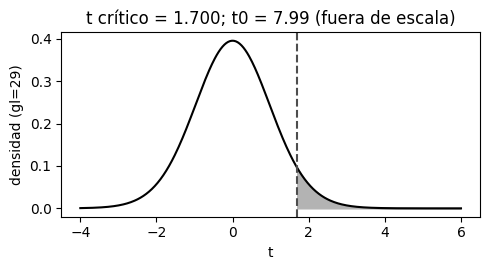

In [8]:
# Figura 1: densidad t con región de rechazo
xs = np.linspace(-4, 6, 400)
ys = [tdist(x, nu) for x in xs]
fig, ax = plt.subplots(figsize=(5, 2.8))
ax.plot(xs, ys, "k")
xr = np.linspace(t_crit, 6, 100)
ax.fill_between(xr, [tdist(x, nu) for x in xr], color="0.7")
ax.axvline(t_crit, ls="--", color="0.3")
ax.set_xlabel("t"); ax.set_ylabel(f"densidad (gl={nu})")
ax.set_title(f"t crítico = {t_crit:.3f}; t0 = {t0:.2f}" + (" (fuera de escala)" if t0 > 6 else ""))
if t0 <= 6: ax.axvline(t0, color="k")
fig.tight_layout(); fig.savefig("fig_t.pdf"); fig.savefig("fig_t.png", dpi=150)

## Prueba 2 · ANOVA de un factor (bomba de calor por franja horaria)
**H0:** el consumo medio de la bomba de calor es el mismo en las tres franjas horarias (madrugada 00–08 h, día 08–16 h, noche 16–24 h).
**H1:** en al menos una franja el consumo medio de la bomba de calor es distinto.

Se usan solo los meses de calefacción (diciembre a febrero), porque la bomba de calor de esta vivienda es de calefacción y vale casi 0 en verano. De cada franja se toman al azar 10 lecturas horarias (kW).

In [9]:
inv = horario[horario.index.month.isin([12, 1, 2])].copy()
inv["franja"] = pd.cut(inv.index.hour, bins=[-1, 7, 15, 23], labels=["Madrugada", "Día", "Noche"])
rng2 = np.random.default_rng(SEMILLA + 1)
grupos = {}
for f in ["Madrugada", "Día", "Noche"]:
    pool = inv.loc[inv["franja"] == f, "heat_pump"].to_numpy()
    grupos[f] = rng2.choice(pool, size=10, replace=False)

datos = list(grupos.values()); k = len(datos); ni = np.array([len(g) for g in datos]); N = ni.sum()
medias = np.array([g.mean() for g in datos]); gran = np.concatenate(datos).mean()
SSTR = float(np.sum(ni * (medias - gran)**2)); SSE = float(sum(np.sum((g - g.mean())**2) for g in datos))
dfT, dfE = k - 1, N - k
MSTR, MSE = SSTR / dfT, SSE / dfE
F0 = MSTR / MSE
p2 = cola_derecha(Fdist, F0, dfT, dfE)
F_crit = critico(Fdist, (dfT, dfE), 1 - ALFA, 0, 0, 10)

print("Medias (kW):", dict(zip(grupos.keys(), medias.round(3))))
print("Desv. est.:", dict(zip(grupos.keys(), [round(g.std(ddof=1), 3) for g in datos])))
print(f"SSTR={SSTR:.4f} SSE={SSE:.4f} SST={SSTR+SSE:.4f} | MSTR={MSTR:.4f} MSE={MSE:.4f}")
print(f"F0 = {F0:.3f}  gl = ({dfT},{dfE})  F_crit = {F_crit:.4f}  p = {p2:.3e}  -> {'se rechaza H0' if p2 < ALFA else 'no se rechaza H0'}")
resultados["prueba2"] = dict(medias=dict(zip(grupos.keys(), medias)), SSTR=SSTR, SSE=SSE, MSTR=MSTR, MSE=MSE,
                              F0=F0, gl=(dfT, dfE), F_crit=F_crit, p=p2)

Medias (kW): {'Madrugada': np.float64(0.856), 'Día': np.float64(0.692), 'Noche': np.float64(0.693)}
Desv. est.: {'Madrugada': np.float64(0.476), 'Día': np.float64(0.218), 'Noche': np.float64(0.213)}
SSTR=0.1776 SSE=2.8736 SST=3.0511 | MSTR=0.0888 MSE=0.1064
F0 = 0.834  gl = (2,27)  F_crit = 3.3542  p = 4.451e-01  -> no se rechaza H0


In [10]:
# Comparaciones por pares (t con el MSE del ANOVA, corrección de Bonferroni: alfa/3)
nombres = list(grupos.keys()); pares = []
se_par = np.sqrt(MSE * 2 / 10)
for i in range(3):
    for j in range(i + 1, 3):
        d = medias[i] - medias[j]; tij = d / se_par
        pij = min(1.0, 2 * cola_derecha(tdist, abs(tij), dfE))
        pares.append(dict(par=f"{nombres[i]} vs {nombres[j]}", dif=d, t=tij, p=pij, signif=pij < ALFA / 3))
        print(f"{nombres[i]:>9} vs {nombres[j]:<9} dif = {d:6.3f} kW  t = {tij:7.3f}  p = {pij:.2e}  {'*' if pij < ALFA/3 else ''}")
resultados["prueba2_pares"] = pares

# Supuestos: homogeneidad de varianzas (cociente máx/mín con la F del formulario) y normalidad de residuos
varz = [g.var(ddof=1) for g in datos]
Fv = max(varz) / min(varz)
pv = min(1.0, 2 * cola_derecha(Fdist, Fv, 9, 9))
print(f"Cociente de varianzas máx/mín = {Fv:.2f}, p (bilateral, orientativo) = {pv:.4f}")
residuos = np.concatenate([g - g.mean() for g in datos])
norm_res = chi2_normalidad(residuos, k=4)
print("Normalidad de residuos: chi2_0 =", round(norm_res['chi2_0'], 4), "| p =", round(norm_res['p'], 4))
resultados["prueba2_supuestos"] = dict(cociente_var=Fv, p_var=pv, normalidad_residuos=norm_res)

Madrugada vs Día       dif =  0.164 kW  t =   1.122  p = 2.72e-01  
Madrugada vs Noche     dif =  0.163 kW  t =   1.115  p = 2.75e-01  
      Día vs Noche     dif = -0.001 kW  t =  -0.007  p = 9.95e-01  
Cociente de varianzas máx/mín = 4.98, p (bilateral, orientativo) = 0.0255
Normalidad de residuos: chi2_0 = 2.8 | p = 0.0943


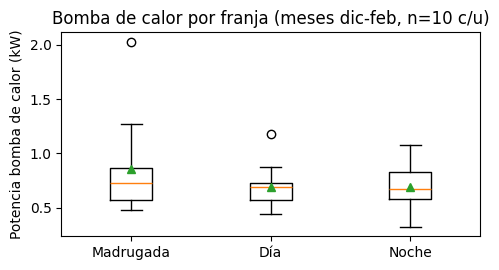

In [11]:
fig, ax = plt.subplots(figsize=(5, 2.8))
ax.boxplot(datos, tick_labels=list(grupos.keys()), showmeans=True)
ax.set_ylabel("Potencia bomba de calor (kW)")
ax.set_title("Bomba de calor por franja (meses dic-feb, n=10 c/u)")
fig.tight_layout(); fig.savefig("fig_anova.pdf"); fig.savefig("fig_anova.png", dpi=150)

## Prueba 3 · Bondad de ajuste χ² (normalidad de la carga nocturna)
**H0:** el consumo eléctrico de la vivienda tomado de la red entre 01:00 y 05:00 h sigue una distribución Normal.
**H1:** el consumo nocturno no sigue una distribución Normal.

Se toman 20 lecturas horarias (kW) de `grid_import` entre las 01:00 y las 05:00 h (carga original, sin orquestador) de cualquier día completo. Con k = 4 clases equiprobables bajo la Normal ajustada, E_i = 5 y ν = 4 − 1 − 2 = 1.

In [12]:
noct = horario[(horario.index.hour >= 1) & (horario.index.hour < 5)]["grid_import"].to_numpy()
rng3 = np.random.default_rng(SEMILLA + 2)
muestra3 = rng3.choice(noct, size=20, replace=False)
r3 = chi2_normalidad(muestra3, k=4)
chi_crit = critico(chi2, (r3['nu'],), 1 - ALFA, 0, 0.0001, 30)
print(f"n = {r3['n']}  mu = {r3['mu']:.4f} kW  sigma = {r3['sigma']:.4f} kW")
print("Frecuencias observadas:", r3['O'], " esperadas:", r3['E'])
print(f"chi2_0 = {r3['chi2_0']:.4f}  gl = {r3['nu']}  chi2_crit = {chi_crit:.4f}  p = {r3['p']:.4f}  -> "
      f"{'se rechaza H0' if r3['p'] < ALFA else 'no se rechaza H0'}")
r3["chi2_crit"] = chi_crit
resultados["prueba3"] = r3

n = 20  mu = 0.5578 kW  sigma = 0.3416 kW
Frecuencias observadas: [8, 0, 7, 5]  esperadas: [5.0, 5.0, 5.0, 5.0]
chi2_0 = 7.6000  gl = 1  chi2_crit = 3.8418  p = 0.0058  -> se rechaza H0


Guardado resultados_estadistica.json


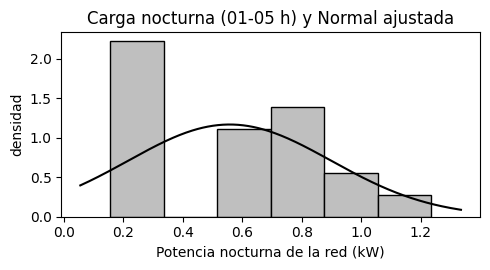

In [13]:
fig, ax = plt.subplots(figsize=(5, 2.8))
ax.hist(muestra3, bins=6, density=True, color="0.75", edgecolor="k")
xs = np.linspace(muestra3.min() - 0.1, muestra3.max() + 0.1, 300)
ax.plot(xs, [gauss(x, r3['mu'], r3['sigma']) for x in xs], "k")
ax.set_xlabel("Potencia nocturna de la red (kW)"); ax.set_ylabel("densidad")
ax.set_title("Carga nocturna (01-05 h) y Normal ajustada")
fig.tight_layout(); fig.savefig("fig_normal.pdf"); fig.savefig("fig_normal.png", dpi=150)

def a_json(o):
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)
json.dump(resultados, open("resultados_estadistica.json", "w"), indent=1, default=a_json, ensure_ascii=False)
print("Guardado resultados_estadistica.json")